# CV

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score

from dataset import load_snli_dataset, convert_to_dataframe
from tokenizer import train_tokenizer
from encoders import TokenIndicator, BagofWords, PairEncoder
from loglin import encode_sparse
from models import FeatureMLP

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

W1104 11:27:53.463000 70696 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps


In [2]:
# settings
SUBSAMPLE = 50_000                 # pairs used for tuning + CV
K = 5                              # folds
SEED = 42
VOCAB_SIZES = [1000, 5000, 10000]  # tuned per system
OVERLAPS = [False, True]           # tuned per system
MAX_EPOCHS = 20                    # MLP epochs tuned per system (1..MAX_EPOCHS)
MLP_ARGS = dict(dropout=0.1, batch_size=64, lr=1e-4, weight_decay=1e-4)  # tutorial values

# name: (encoder, model, hidden layers)
SYSTEMS = {
    "ti_loglin":  ("indicator", "loglin", None),
    "bow_loglin": ("bow",       "loglin", None),
    "ti_mlp1":    ("indicator", "mlp", (128,)),
    "bow_mlp1":   ("bow",       "mlp", (128,)),
    "ti_mlp2":    ("indicator", "mlp", (128, 64)),   # third model: extra hidden layer
    "bow_mlp2":   ("bow",       "mlp", (128, 64)),
    "st_loglin":  ("st",        "loglin", None),     # third representation: sentence-transformer embeddings
    "st_mlp1":    ("st",        "mlp", (128,)),
    "st_mlp2":    ("st",        "mlp", (128, 64)),
}

In [3]:
# data
train_df, val_df, test_df = convert_to_dataframe(load_snli_dataset())

sub = train_df.sample(SUBSAMPLE, random_state=0)
pairs = list(zip(sub["premise"], sub["hypothesis"]))
labels = sub["label"].to_numpy()
groups = sub["premise"].to_numpy()          # folds grouped by premise

val_pairs = list(zip(val_df["premise"], val_df["hypothesis"]))
val_labels = val_df["label"].to_numpy()
print(len(pairs), np.bincount(labels), len(val_pairs))

50000 [16745 16627 16628] 9842


In [4]:
def fit_tokenizer(pair_list, vocab_size):
    premises = list({p for p, _ in pair_list})  # premises repeat ~3x in SNLI, dedupe
    hyps = [h for _, h in pair_list]
    return train_tokenizer(premises + hyps, vocab_size, min_frequency=2)

def encode(pair_list, tok, kind, overlap):
    base = TokenIndicator(tok) if kind == "indicator" else BagofWords(tok)
    return encode_sparse(pair_list, PairEncoder(base, overlap=overlap))

In [5]:
# third representation: sentence-transformer embeddings (the team's model, nli-mpnet-base-v2)
# note: this model was trained on SNLI + MultiNLI, so its scores are optimistic
from sentence_transformers import SentenceTransformer

st_device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
sentence_model = SentenceTransformer("sentence-transformers/nli-mpnet-base-v2", device=st_device)

def st_encode_pairs(pair_list, batch_size=256):
    # same as Tony's encode_pairs (scratch_notebook): [premise vector ; hypothesis vector]
    u = sentence_model.encode([p for p, _ in pair_list], batch_size=batch_size, convert_to_numpy=True, show_progress_bar=True)
    v = sentence_model.encode([h for _, h in pair_list], batch_size=batch_size, convert_to_numpy=True, show_progress_bar=True)
    return np.concatenate([u, v], axis=1).astype(np.float32)

# the encoder is pretrained and fixed (nothing is fitted on our folds), so encode once and index per fold
ST_TRAIN = st_encode_pairs(pairs)
ST_VAL = st_encode_pairs(val_pairs)
print(ST_TRAIN.shape, ST_VAL.shape)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.64k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/587 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (8 outputs left out)

Batches:   0%|          | 0/196 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

(50000, 1536) (9842, 1536)


In [6]:
# models
def dense(X):
    return X.toarray() if hasattr(X, "toarray") else X  # sparse token vectors -> dense batch; embeddings are already dense


def fit_loglin(X, y):
    return LogisticRegression(solver="saga", max_iter=100, random_state=SEED).fit(X, y)


def mlp_predict(model, X):
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, X.shape[0], 2048):
            out.append(model(torch.as_tensor(dense(X[s:s + 2048]), device=DEVICE)).argmax(-1).cpu().numpy())
    return np.concatenate(out)


def mlp_epochs(X, y, hidden, epochs, dropout=0.1, batch_size=64, lr=1e-4, weight_decay=1e-4):
    # our FeatureMLP on sparse inputs (batches densified on the fly);
    # yields (epoch, model) after every epoch so we can score along the way
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = FeatureMLP(X.shape[1], hidden_dims=hidden, dropout=dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = torch.nn.CrossEntropyLoss()
    y_t = torch.as_tensor(y, dtype=torch.long)
    for e in range(1, epochs + 1):
        model.train()
        perm = rng.permutation(X.shape[0])
        for s in range(0, len(perm), batch_size):
            b = perm[s:s + batch_size]
            opt.zero_grad()
            loss_fn(model(torch.as_tensor(dense(X[b]), device=DEVICE)), y_t[b].to(DEVICE)).backward()
            opt.step()
        yield e, model


def fit_mlp(X, y, hidden, epochs):
    for _, m in mlp_epochs(X, y, hidden, epochs, **MLP_ARGS):
        pass
    return m


def predict(model, X):
    return model.predict(X) if isinstance(model, LogisticRegression) else mlp_predict(model, X)

In [7]:
%%time
# each (vocab, encoder, overlap) is encoded once and reused for all models of that encoder
tuning = []
for V in VOCAB_SIZES:
    tok = fit_tokenizer(pairs, V)
    for kind in ["indicator", "bow"]:
        for ov in OVERLAPS:
            Xtr, Xva = encode(pairs, tok, kind, ov), encode(val_pairs, tok, kind, ov)
            for name, (k, model, hidden) in SYSTEMS.items():
                if k != kind:
                    continue
                t0 = time.time()
                if model == "loglin":
                    runs = [(None, fit_loglin(Xtr, labels))]
                else:
                    runs = mlp_epochs(Xtr, labels, hidden, MAX_EPOCHS, **MLP_ARGS)
                for e, m in runs:
                    tr_acc = accuracy_score(labels, predict(m, Xtr))
                    va_acc = accuracy_score(val_labels, predict(m, Xva))
                    tuning.append(dict(system=name, vocab=V, overlap=ov, epochs=e, train_acc=tr_acc, val_acc=va_acc))
                    ep = f"epoch {e:>2}" if e else "        "
                    print(f"{name:<11} vocab {V:>5} overlap {ov!s:<5} {ep}  train {tr_acc:.4f}  val {va_acc:.4f}")
                print(f"  ({time.time() - t0:.0f}s)")

# sentence-transformer systems: no vocab size / overlap (fixed pretrained encoder), only MLP epochs to tune
for name, (k, model, hidden) in SYSTEMS.items():
    if k != "st":
        continue
    t0 = time.time()
    if model == "loglin":
        runs = [(None, fit_loglin(ST_TRAIN, labels))]
    else:
        runs = mlp_epochs(ST_TRAIN, labels, hidden, MAX_EPOCHS, **MLP_ARGS)
    for e, m in runs:
        tr_acc = accuracy_score(labels, predict(m, ST_TRAIN))
        va_acc = accuracy_score(val_labels, predict(m, ST_VAL))
        tuning.append(dict(system=name, vocab=None, overlap=None, epochs=e, train_acc=tr_acc, val_acc=va_acc))
        ep = f"epoch {e:>2}" if e else "        "
        print(f"{name:<11} {ep}  train {tr_acc:.4f}  val {va_acc:.4f}")
    print(f"  ({time.time() - t0:.0f}s)")

tuning = pd.DataFrame(tuning)

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/var/folders/xh/4nrbxdbj4bs4ffn8tsbf4_840000gn/T/ipykernel_70696/3890932922.py:27: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  y_t = torch.as_tensor(y, dtype=torch.long)


ti_loglin   vocab  1000 overlap False           train 0.6335  val 0.5987
  (1s)
ti_mlp1     vocab  1000 overlap False epoch  1  train 0.5678  val 0.5541
ti_mlp1     vocab  1000 overlap False epoch  2  train 0.6010  val 0.5770
ti_mlp1     vocab  1000 overlap False epoch  3  train 0.6146  val 0.5842
ti_mlp1     vocab  1000 overlap False epoch  4  train 0.6209  val 0.5886
ti_mlp1     vocab  1000 overlap False epoch  5  train 0.6270  val 0.5951
ti_mlp1     vocab  1000 overlap False epoch  6  train 0.6306  val 0.5971
ti_mlp1     vocab  1000 overlap False epoch  7  train 0.6346  val 0.5963
ti_mlp1     vocab  1000 overlap False epoch  8  train 0.6383  val 0.6018
ti_mlp1     vocab  1000 overlap False epoch  9  train 0.6408  val 0.5993
ti_mlp1     vocab  1000 overlap False epoch 10  train 0.6445  val 0.6018
ti_mlp1     vocab  1000 overlap False epoch 11  train 0.6508  val 0.6046
ti_mlp1     vocab  1000 overlap False epoch 12  train 0.6559  val 0.6039
ti_mlp1     vocab  1000 overlap False epoch 

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


ti_loglin   vocab  1000 overlap True            train 0.7224  val 0.6775
  (1s)
ti_mlp1     vocab  1000 overlap True  epoch  1  train 0.6095  val 0.5925
ti_mlp1     vocab  1000 overlap True  epoch  2  train 0.6548  val 0.6303
ti_mlp1     vocab  1000 overlap True  epoch  3  train 0.6726  val 0.6456
ti_mlp1     vocab  1000 overlap True  epoch  4  train 0.6832  val 0.6543
ti_mlp1     vocab  1000 overlap True  epoch  5  train 0.6936  val 0.6612
ti_mlp1     vocab  1000 overlap True  epoch  6  train 0.7006  val 0.6648
ti_mlp1     vocab  1000 overlap True  epoch  7  train 0.7035  val 0.6673
ti_mlp1     vocab  1000 overlap True  epoch  8  train 0.7092  val 0.6713
ti_mlp1     vocab  1000 overlap True  epoch  9  train 0.7150  val 0.6697
ti_mlp1     vocab  1000 overlap True  epoch 10  train 0.7195  val 0.6744
ti_mlp1     vocab  1000 overlap True  epoch 11  train 0.7253  val 0.6757
ti_mlp1     vocab  1000 overlap True  epoch 12  train 0.7293  val 0.6738
ti_mlp1     vocab  1000 overlap True  epoch 

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


bow_loglin  vocab  1000 overlap False           train 0.6326  val 0.5946
  (1s)
bow_mlp1    vocab  1000 overlap False epoch  1  train 0.5664  val 0.5486
bow_mlp1    vocab  1000 overlap False epoch  2  train 0.5996  val 0.5755
bow_mlp1    vocab  1000 overlap False epoch  3  train 0.6139  val 0.5849
bow_mlp1    vocab  1000 overlap False epoch  4  train 0.6192  val 0.5884
bow_mlp1    vocab  1000 overlap False epoch  5  train 0.6268  val 0.5958
bow_mlp1    vocab  1000 overlap False epoch  6  train 0.6307  val 0.5994
bow_mlp1    vocab  1000 overlap False epoch  7  train 0.6354  val 0.5976
bow_mlp1    vocab  1000 overlap False epoch  8  train 0.6391  val 0.6010
bow_mlp1    vocab  1000 overlap False epoch  9  train 0.6427  val 0.6008
bow_mlp1    vocab  1000 overlap False epoch 10  train 0.6472  val 0.6028
bow_mlp1    vocab  1000 overlap False epoch 11  train 0.6537  val 0.6040
bow_mlp1    vocab  1000 overlap False epoch 12  train 0.6586  val 0.6029
bow_mlp1    vocab  1000 overlap False epoch 

... (14 outputs left out)

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


bow_loglin  vocab 10000 overlap False           train 0.8080  val 0.6033
  (1s)
bow_mlp1    vocab 10000 overlap False epoch  1  train 0.6075  val 0.5580
bow_mlp1    vocab 10000 overlap False epoch  2  train 0.6683  val 0.5872
bow_mlp1    vocab 10000 overlap False epoch  3  train 0.7048  val 0.6039
bow_mlp1    vocab 10000 overlap False epoch  4  train 0.7277  val 0.6084
bow_mlp1    vocab 10000 overlap False epoch  5  train 0.7470  val 0.6114
bow_mlp1    vocab 10000 overlap False epoch  6  train 0.7622  val 0.6094
bow_mlp1    vocab 10000 overlap False epoch  7  train 0.7733  val 0.6118
bow_mlp1    vocab 10000 overlap False epoch  8  train 0.7848  val 0.6083
bow_mlp1    vocab 10000 overlap False epoch  9  train 0.7939  val 0.6022
bow_mlp1    vocab 10000 overlap False epoch 10  train 0.8019  val 0.6042
bow_mlp1    vocab 10000 overlap False epoch 11  train 0.8099  val 0.6038
bow_mlp1    vocab 10000 overlap False epoch 12  train 0.8172  val 0.6035
bow_mlp1    vocab 10000 overlap False epoch 

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


bow_loglin  vocab 10000 overlap True            train 0.8522  val 0.6421
  (1s)
bow_mlp1    vocab 10000 overlap True  epoch  1  train 0.6297  val 0.5773
bow_mlp1    vocab 10000 overlap True  epoch  2  train 0.7022  val 0.6158
bow_mlp1    vocab 10000 overlap True  epoch  3  train 0.7401  val 0.6278
bow_mlp1    vocab 10000 overlap True  epoch  4  train 0.7656  val 0.6368
bow_mlp1    vocab 10000 overlap True  epoch  5  train 0.7876  val 0.6403
bow_mlp1    vocab 10000 overlap True  epoch  6  train 0.8039  val 0.6412
bow_mlp1    vocab 10000 overlap True  epoch  7  train 0.8153  val 0.6456
bow_mlp1    vocab 10000 overlap True  epoch  8  train 0.8274  val 0.6410
bow_mlp1    vocab 10000 overlap True  epoch  9  train 0.8394  val 0.6425
bow_mlp1    vocab 10000 overlap True  epoch 10  train 0.8487  val 0.6405
bow_mlp1    vocab 10000 overlap True  epoch 11  train 0.8573  val 0.6408
bow_mlp1    vocab 10000 overlap True  epoch 12  train 0.8642  val 0.6380
bow_mlp1    vocab 10000 overlap True  epoch 

In [8]:
# best setting per system (ties -> first found = smaller vocab / no overlap / fewer epochs)
BEST = tuning.loc[tuning.groupby("system", sort=False)["val_acc"].idxmax()].set_index("system")
BEST

,vocab,overlap,epochs,train_acc,val_acc
system,,,,,
ti_loglin,1000.0,True,NaN,0.72242,0.677505
ti_mlp1,1000.0,True,20.0,0.76972,0.682686
ti_mlp2,1000.0,True,11.0,0.81142,0.682991
bow_loglin,1000.0,True,NaN,0.72092,0.675066
bow_mlp1,1000.0,True,20.0,0.77182,0.681061
bow_mlp2,1000.0,True,12.0,0.83670,0.680146
st_loglin,NaN,None,NaN,0.67494,0.652002
st_mlp1,NaN,None,19.0,0.78464,0.746393
st_mlp2,NaN,None,17.0,0.85200,0.761227


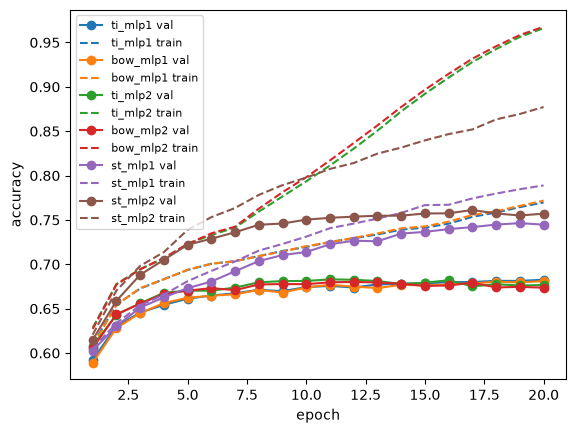

In [9]:
# MLP curves at each system's best vocab/overlap (solid = val, dashed = train)
for name in [n for n in SYSTEMS if SYSTEMS[n][1] == "mlp"]:
    b = BEST.loc[name]
    same = lambda col: (tuning[col] == b[col]) | (tuning[col].isna() & pd.isna(b[col]))
    c = tuning[(tuning.system == name) & same("vocab") & same("overlap")]
    line, = plt.plot(c.epochs, c.val_acc, marker="o", label=f"{name} val")
    plt.plot(c.epochs, c.train_acc, ls="--", color=line.get_color(), label=f"{name} train")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(fontsize=8); plt.show()

## Cross-validation with each system's best setting (same folds for all, tokenizer retrained per fold)

In [10]:
%%time
folds = list(GroupKFold(n_splits=K).split(pairs, labels, groups))
results = []
for f, (tr, va) in enumerate(folds):
    t0 = time.time()
    P_tr, P_va = [pairs[i] for i in tr], [pairs[i] for i in va]
    toks = {int(V): fit_tokenizer(P_tr, int(V)) for V in BEST.vocab.dropna().unique()}   # tokenizer only sees the training folds
    cache = {}
    for name, (kind, model, hidden) in SYSTEMS.items():
        b = BEST.loc[name]
        if kind == "st":
            Xtr, Xva = ST_TRAIN[tr], ST_TRAIN[va]
        else:
            key = (int(b.vocab), kind, bool(b.overlap))
            if key not in cache:                 # encode once, reuse for all models with the same setting
                tok = toks[key[0]]
                cache[key] = (encode(P_tr, tok, kind, key[2]), encode(P_va, tok, kind, key[2]))
            Xtr, Xva = cache[key]
        m = fit_loglin(Xtr, labels[tr]) if model == "loglin" else fit_mlp(Xtr, labels[tr], hidden, int(b.epochs))
        preds = predict(m, Xva)
        results.append(dict(system=name, fold=f,
                            train_accuracy=accuracy_score(labels[tr], predict(m, Xtr)),
                            accuracy=accuracy_score(labels[va], preds),
                            macro_f1=f1_score(labels[va], preds, average="macro")))
        r = results[-1]
        print(f"fold {f}  {name:<11} train {r['train_accuracy']:.4f}  val {r['accuracy']:.4f}")
    print(f"fold {f} done in {time.time() - t0:.0f}s\n")

scores = pd.DataFrame(results)

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


fold 0  ti_loglin   train 0.7268  val 0.6665


/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


fold 0  bow_loglin  train 0.7248  val 0.6637
fold 0  ti_mlp1     train 0.7635  val 0.6688
fold 0  bow_mlp1    train 0.7657  val 0.6662
fold 0  ti_mlp2     train 0.7996  val 0.6686
fold 0  bow_mlp2    train 0.8213  val 0.6653
fold 0  st_loglin   train 0.6779  val 0.6468
fold 0  st_mlp1     train 0.7738  val 0.7301
fold 0  st_mlp2     train 0.8459  val 0.7453
fold 0 done in 130s






/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


fold 1  ti_loglin   train 0.7292  val 0.6587


... (10 outputs left out)

/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


fold 4  ti_loglin   train 0.7281  val 0.6617


/Users/vaibhav/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


fold 4  bow_loglin  train 0.7252  val 0.6589
fold 4  ti_mlp1     train 0.7634  val 0.6640
fold 4  bow_mlp1    train 0.7647  val 0.6606
fold 4  ti_mlp2     train 0.8032  val 0.6648
fold 4  bow_mlp2    train 0.8209  val 0.6579
fold 4  st_loglin   train 0.6799  val 0.6370
fold 4  st_mlp1     train 0.7738  val 0.7192
fold 4  st_mlp2     train 0.8481  val 0.7383
fold 4 done in 125s

CPU times: user 8min 42s, sys: 1min 16s, total: 9min 58s
Wall time: 46min 32s


## Results

In [11]:
summary = scores.groupby("system")[["train_accuracy", "accuracy", "macro_f1"]].agg(["mean", "std"]).sort_values(("accuracy", "mean"), ascending=False)
order = summary.index.tolist()
summary.round(4)

train_accuracy         accuracy         macro_f1        
                     mean     std     mean     std     mean     std
system                                                             
st_mlp2            0.8472  0.0015   0.7399  0.0033   0.7396  0.0037
st_mlp1            0.7741  0.0004   0.7231  0.0055   0.7220  0.0055
ti_mlp1            0.7645  0.0021   0.6645  0.0056   0.6632  0.0060
ti_mlp2            0.8022  0.0066   0.6645  0.0062   0.6635  0.0061
bow_mlp1           0.7650  0.0015   0.6637  0.0051   0.6625  0.0052
ti_loglin          0.7277  0.0012   0.6628  0.0030   0.6608  0.0031
bow_mlp2           0.8214  0.0059   0.6624  0.0040   0.6611  0.0040
bow_loglin         0.7254  0.0009   0.6618  0.0036   0.6599  0.0034
st_loglin          0.6787  0.0012   0.6428  0.0041   0.6421  0.0042

## ROPE 

In [25]:
from eval import BenavoliCorrelatedT

ROPE = 0.01
accs = [scores[scores.system == s].sort_values("fold")["accuracy"].to_numpy() for s in order]
bct = BenavoliCorrelatedT(accs, system_names=order)

p_a, p_tie, p_b = bct.probs(ROPE)
names = [(order[i], order[j]) for i in range(len(order)) for j in range(i + 1, len(order))]
pd.DataFrame(dict(A=[a for a, _ in names], B=[b for _, b in names],
                  mean_diff_B_minus_A=bct.mean_diffs,
                  P_A_wins=p_a, P_tie=p_tie, P_B_wins=p_b)).round(3)

,A,B,mean_diff_B_minus_A,P_A_wins,P_tie,P_B_wins
0,st_mlp2,st_mlp1,-0.017,0.979,0.021,0.000
1,st_mlp2,ti_mlp1,-0.075,1.000,0.000,0.000
2,st_mlp2,ti_mlp2,-0.075,1.000,0.000,0.000
3,st_mlp2,bow_mlp1,-0.076,1.000,0.000,0.000
4,st_mlp2,ti_loglin,-0.077,1.000,0.000,0.000
5,st_mlp2,bow_mlp2,-0.077,1.000,0.000,0.000
6,st_mlp2,bow_loglin,-0.078,1.000,0.000,0.000
7,st_mlp2,st_loglin,-0.097,1.000,0.000,0.000
8,st_mlp1,ti_mlp1,-0.059,1.000,0.000,0.000
9,st_mlp1,ti_mlp2,-0.059,0.999,0.000,0.000


In [27]:
accs

[array([0.7453, 0.7397, 0.7393, 0.7367, 0.7383]),
 array([0.7301, 0.7279, 0.7188, 0.7193, 0.7192]),
 array([0.6688, 0.6586, 0.6715, 0.6596, 0.664 ]),
 array([0.6686, 0.6565, 0.672 , 0.6604, 0.6648]),
 array([0.6662, 0.658 , 0.6711, 0.6628, 0.6606]),
 array([0.6665, 0.6587, 0.6648, 0.6623, 0.6617]),
 array([0.6653, 0.6596, 0.6676, 0.6616, 0.6579]),
 array([0.6637, 0.6571, 0.6646, 0.6649, 0.6589]),
 array([0.6468, 0.6466, 0.643 , 0.6407, 0.637 ])]

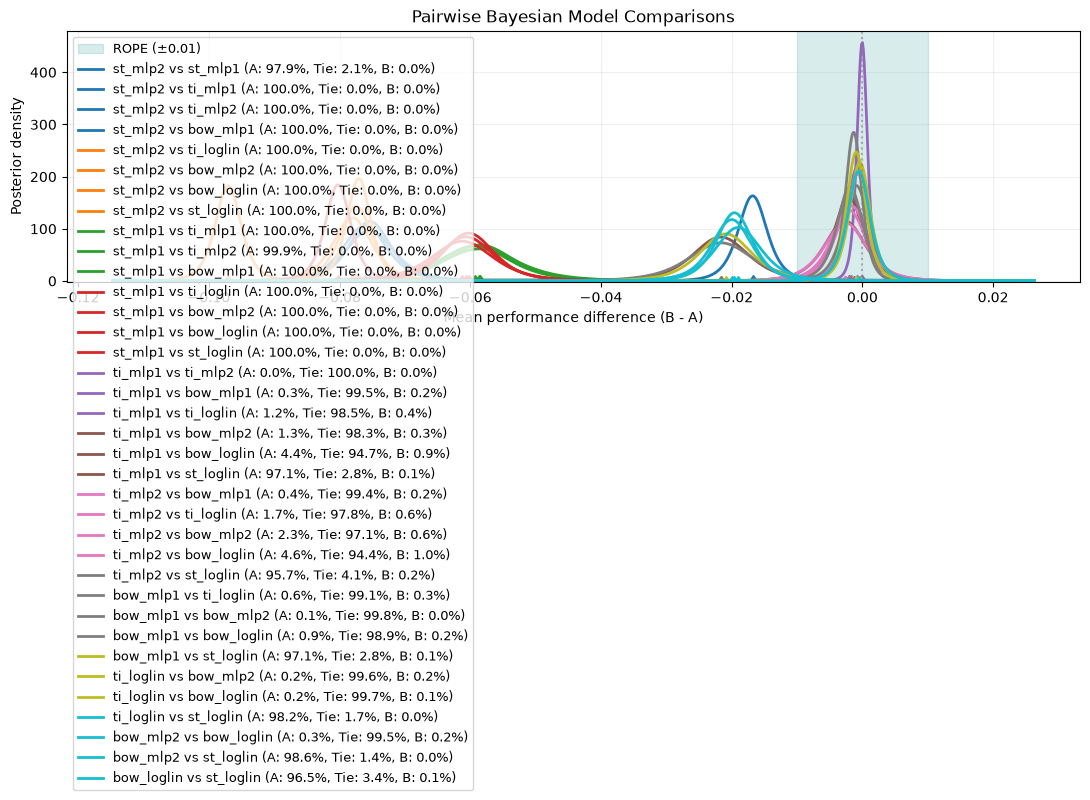

In [26]:
fig, ax = bct.plot_all_systems(ROPE)
plt.show()

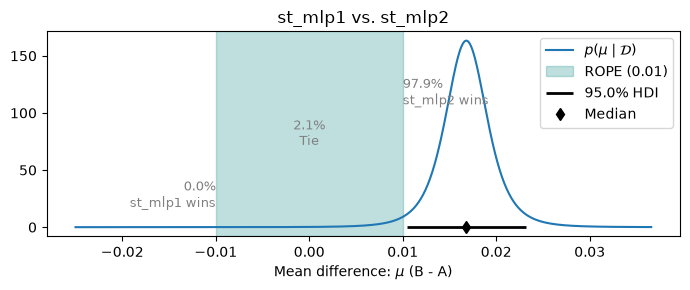

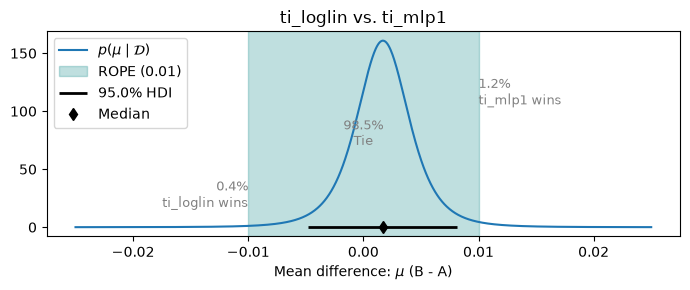

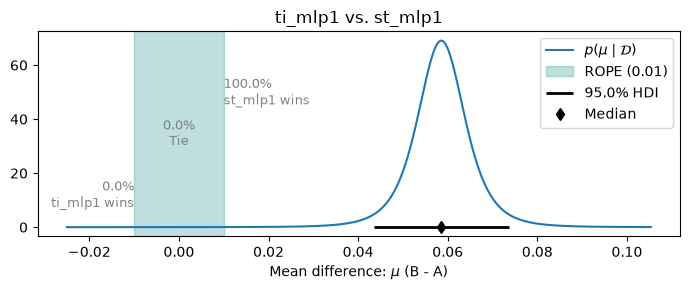

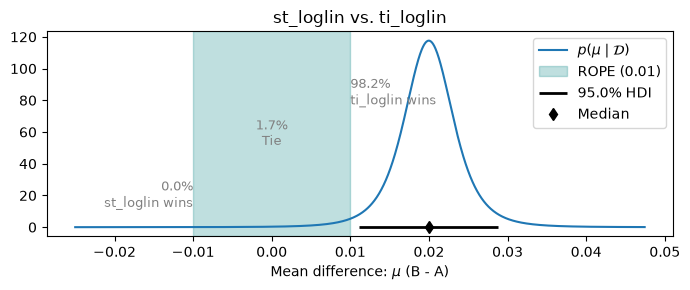

In [28]:
pairs_to_show = [("st_mlp1", "st_mlp2"), ("ti_loglin", "ti_mlp1"), ("ti_mlp1", "st_mlp1"), ("st_loglin", "ti_loglin")]
for A, B in pairs_to_show:
    p = BenavoliCorrelatedT([accs[order.index(A)], accs[order.index(B)]], system_names=[A, B])
    fig, axes = p.plot(ROPE)
    fig.set_size_inches(7, 3); fig.tight_layout(); plt.show()

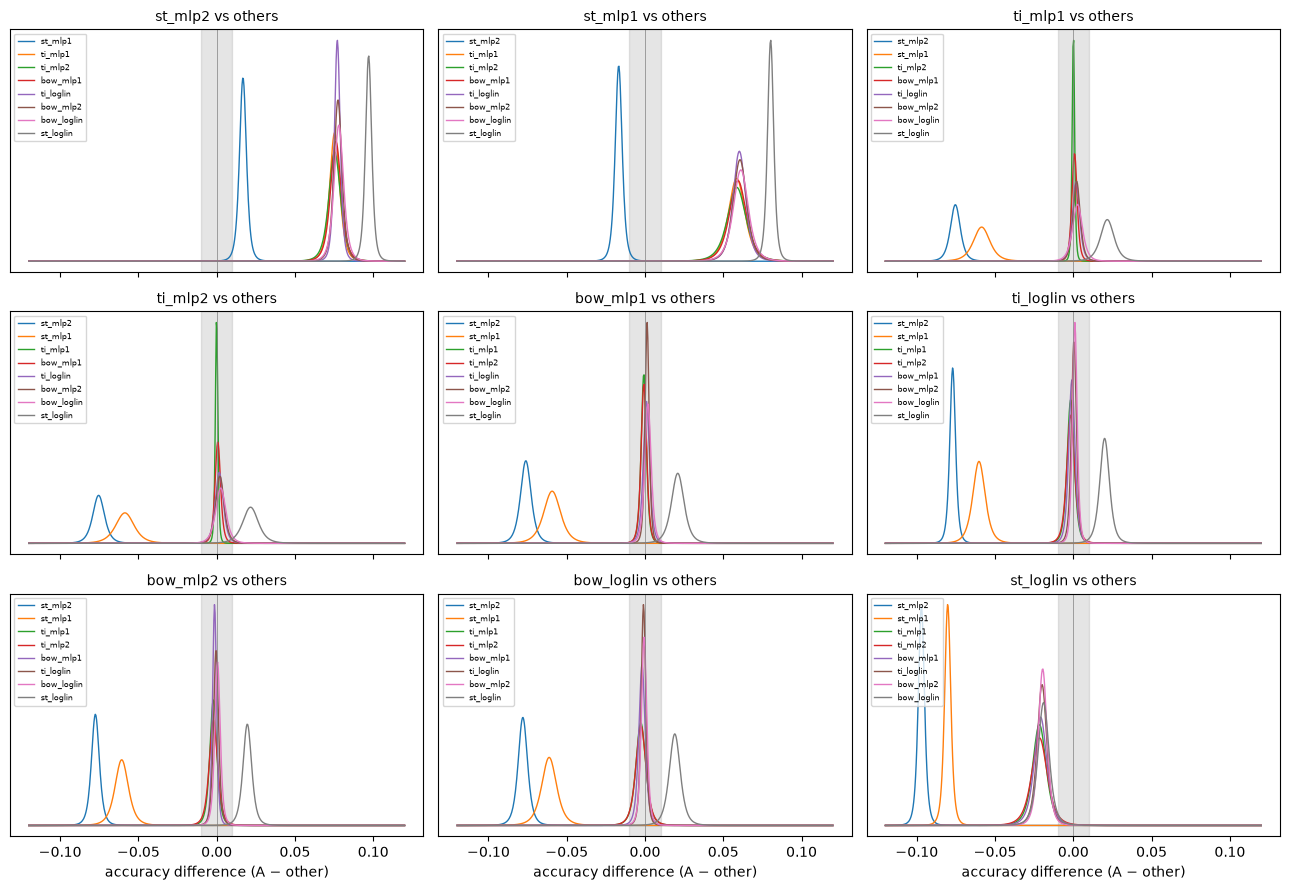

In [29]:
import scipy.stats as st

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
x = np.linspace(-0.12, 0.12, 600)

for ax, A in zip(axes.flat, order):
    for B in order:
        if B == A:
            continue
        p = BenavoliCorrelatedT([accs[order.index(A)], accs[order.index(B)]], system_names=[A, B])
        # posterior of (B - A), flipped to (A - B) so right of the ROPE = A is better
        t = st.t(df=p.dfs[0], loc=-p.mean_diffs[0], scale=p.stds[0])
        ax.plot(x, t.pdf(x), lw=1, label=B)
    ax.axvspan(-ROPE, ROPE, color="grey", alpha=0.2)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(f"{A} vs others", fontsize=10)
    ax.set_yticks([])
    ax.legend(fontsize=6, loc="upper left")

for ax in axes[-1]:
    ax.set_xlabel("accuracy difference (A − other)")
fig.tight_layout()
plt.show()

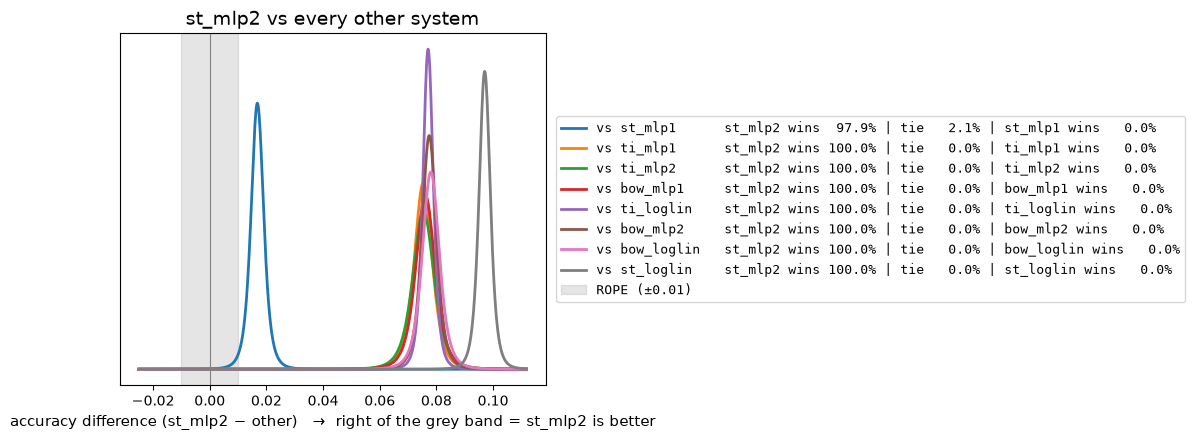

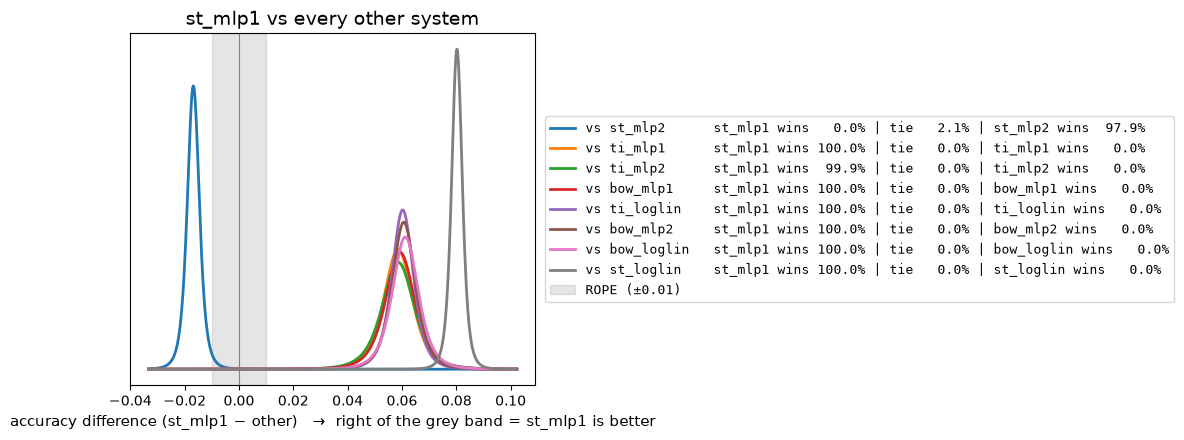

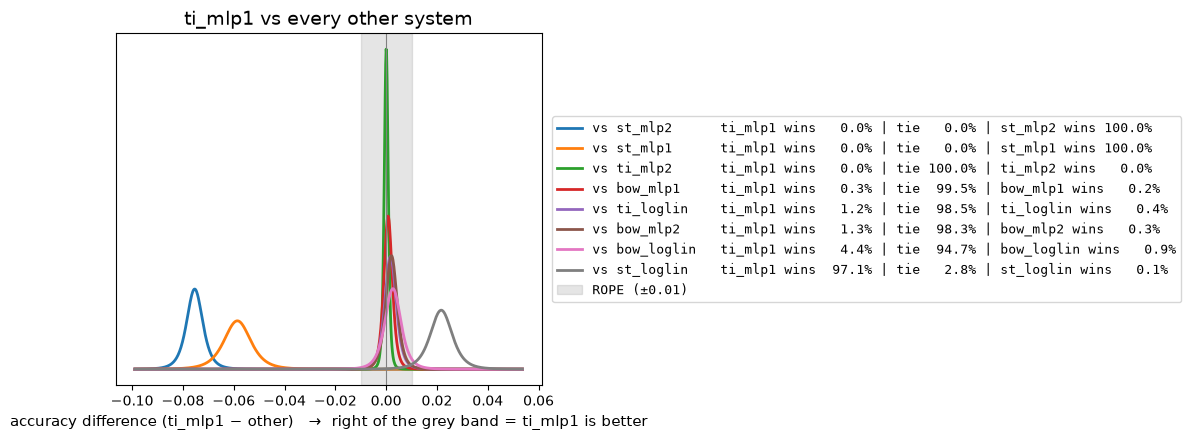

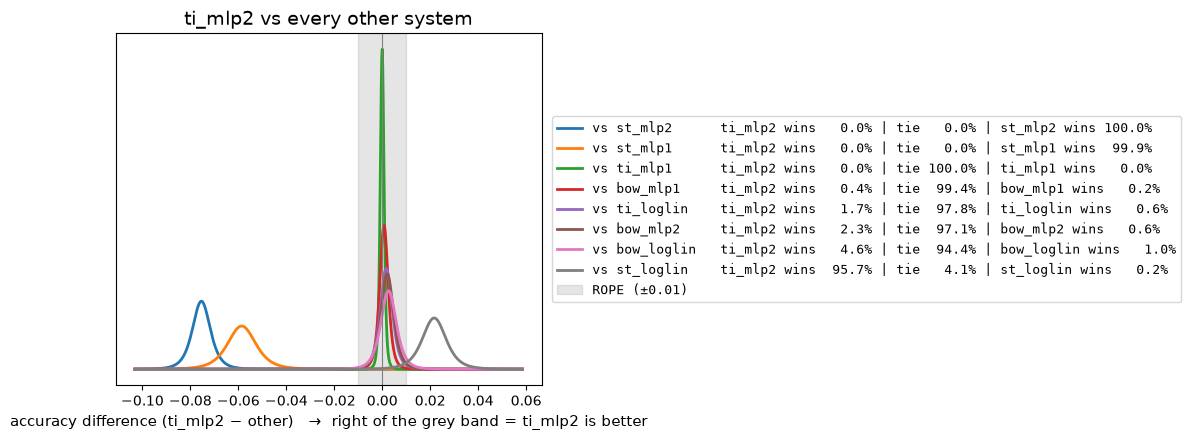

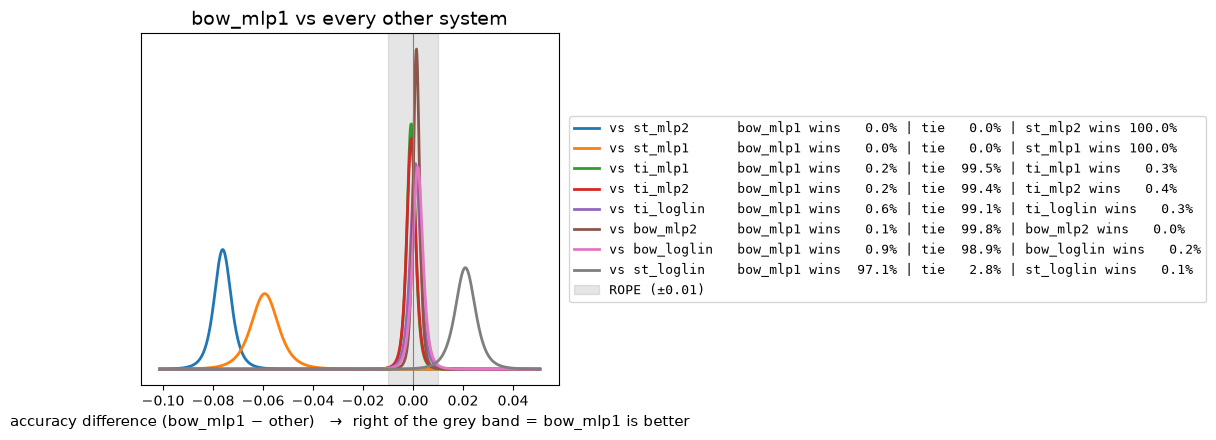

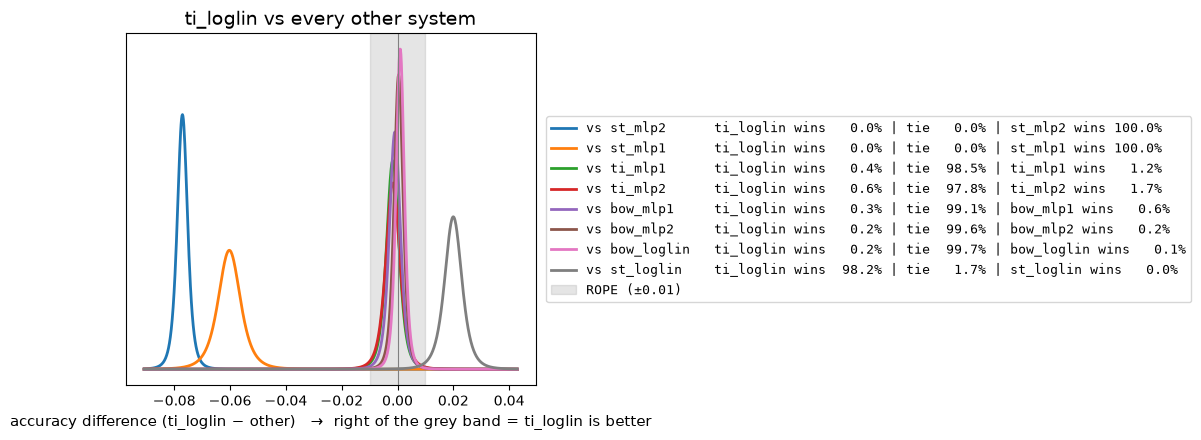

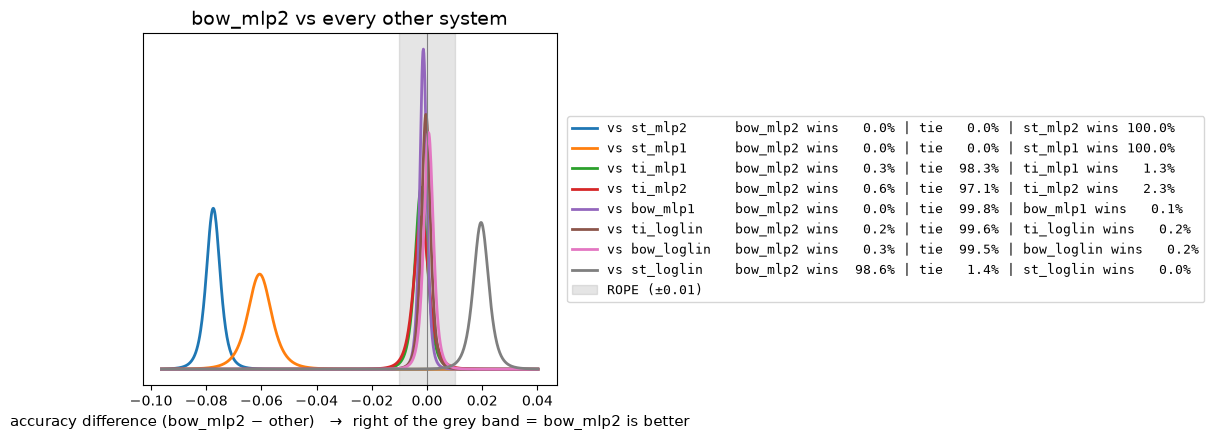

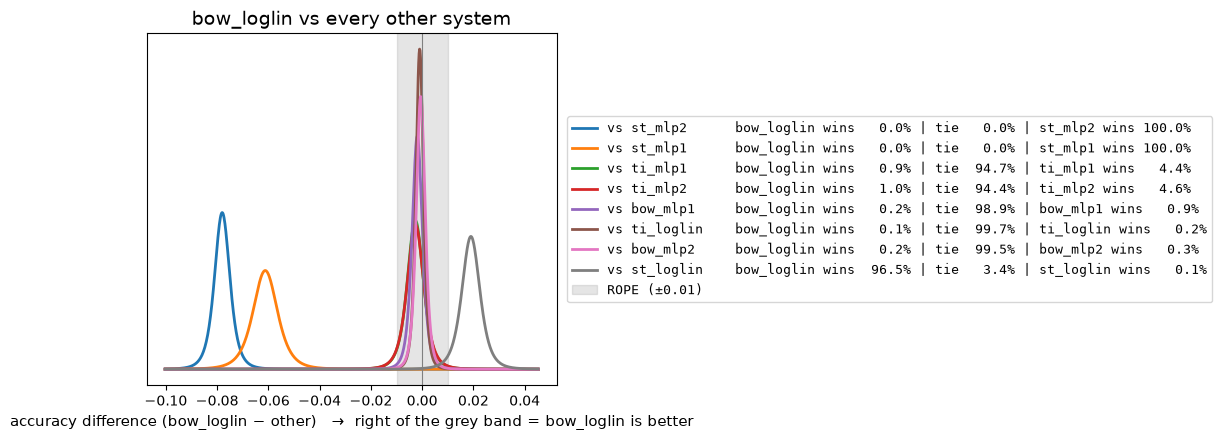

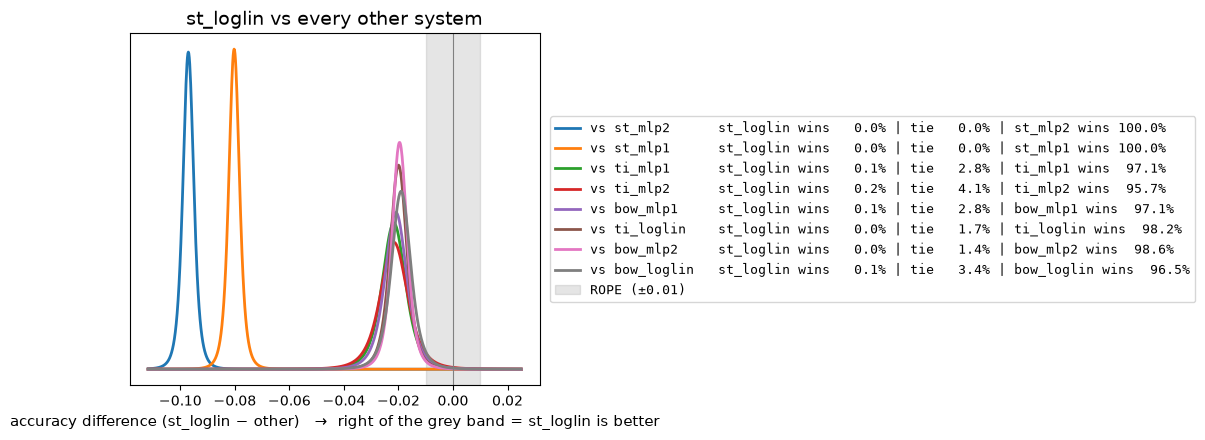

In [30]:
import scipy.stats as st

for A in order:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    curves = []
    for B in order:
        if B == A:
            continue
        p = BenavoliCorrelatedT([accs[order.index(A)], accs[order.index(B)]], system_names=[A, B])
        p_a, p_tie, p_b = [float(np.ravel(v)[0]) for v in p.probs(ROPE)]   # A wins / tie / B wins
        # posterior of (B - A), flipped to (A - B): right of the ROPE = A is better
        curves.append((B, st.t(df=p.dfs[0], loc=-p.mean_diffs[0], scale=p.stds[0]), p_a, p_tie, p_b))

    lo = min(min(t.ppf(0.001) for _, t, *_ in curves), -2.5 * ROPE)
    hi = max(max(t.ppf(0.999) for _, t, *_ in curves), 2.5 * ROPE)
    x = np.linspace(lo, hi, 800)
    for B, t, p_a, p_tie, p_b in curves:
        ax.plot(x, t.pdf(x), lw=2,
                label=f"vs {B:<11}  {A} wins {p_a:6.1%} | tie {p_tie:6.1%} | {B} wins {p_b:6.1%}")

    ax.axvspan(-ROPE, ROPE, color="grey", alpha=0.2, label=f"ROPE (±{ROPE})")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{A} vs every other system", fontsize=14)
    ax.set_xlabel(f"accuracy difference ({A} − other)   →  right of the grey band = {A} is better", fontsize=11)
    ax.set_yticks([])
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5), prop={"family": "monospace", "size": 9})
    fig.tight_layout()
    plt.show()

## Best model (st_mlp2): CV tuning, then train on the full training set

In [13]:
%%time
# CV-based tuning of st_mlp2 on the 50k subsample (same folds as above); epochs 1..MAX_EPOCHS recorded in every run
GRID = [dict(hidden=h, dropout=d, lr=lr)
        for h in [(128, 64), (256, 128), (512, 256)]
        for d in [0.1, 0.3]
        for lr in [1e-4, 1e-3]]

cv_tuning = []
for g in GRID:
    t0 = time.time()
    args = dict(MLP_ARGS, dropout=g["dropout"], lr=g["lr"])
    for f, (tr, va) in enumerate(folds):
        for e, m in mlp_epochs(ST_TRAIN[tr], labels[tr], g["hidden"], MAX_EPOCHS, **args):
            cv_tuning.append(dict(hidden=g["hidden"], dropout=g["dropout"], lr=g["lr"], fold=f, epochs=e,
                                  val_acc=accuracy_score(labels[va], predict(m, ST_TRAIN[va]))))
    print(g, f"({time.time() - t0:.0f}s)")

cv_tuning = pd.DataFrame(cv_tuning)
cv_mean = (cv_tuning.groupby(["hidden", "dropout", "lr", "epochs"])["val_acc"]
           .agg(["mean", "std"]).reset_index().sort_values("mean", ascending=False))
FINAL = cv_mean.iloc[0]   # best setting by mean CV accuracy (this mean is a bit optimistic: it's the max over many settings)
print("best:", dict(FINAL))
cv_mean.head(10).round(4)

{'hidden': (128, 64), 'dropout': 0.1, 'lr': 0.0001} (82s)
{'hidden': (128, 64), 'dropout': 0.1, 'lr': 0.001} (84s)
{'hidden': (128, 64), 'dropout': 0.3, 'lr': 0.0001} (86s)
{'hidden': (128, 64), 'dropout': 0.3, 'lr': 0.001} (89s)
{'hidden': (256, 128), 'dropout': 0.1, 'lr': 0.0001} (94s)
{'hidden': (256, 128), 'dropout': 0.1, 'lr': 0.001} (90s)
{'hidden': (256, 128), 'dropout': 0.3, 'lr': 0.0001} (102s)
{'hidden': (256, 128), 'dropout': 0.3, 'lr': 0.001} (87s)
{'hidden': (512, 256), 'dropout': 0.1, 'lr': 0.0001} (92s)
{'hidden': (512, 256), 'dropout': 0.1, 'lr': 0.001} (96s)
{'hidden': (512, 256), 'dropout': 0.3, 'lr': 0.0001} (91s)
{'hidden': (512, 256), 'dropout': 0.3, 'lr': 0.001} (92s)
best: {'hidden': (512, 256), 'dropout': np.float64(0.3), 'lr': np.float64(0.0001), 'epochs': np.int64(15), 'mean': np.float64(0.74778), 'std': np.float64(0.006382946028285038)}
CPU times: user 11min, sys: 2min 44s, total: 13min 44s
Wall time: 18min 4s


,hidden,dropout,lr,epochs,mean,std
214,"(512, 256)",0.3,0.0001,15,0.7478,0.0064
213,"(512, 256)",0.3,0.0001,14,0.7477,0.0029
218,"(512, 256)",0.3,0.0001,19,0.7475,0.0042
215,"(512, 256)",0.3,0.0001,16,0.7474,0.0050
212,"(512, 256)",0.3,0.0001,13,0.7473,0.0049
211,"(512, 256)",0.3,0.0001,12,0.7468,0.0068
209,"(512, 256)",0.3,0.0001,10,0.7468,0.0055
210,"(512, 256)",0.3,0.0001,11,0.7466,0.0068
208,"(512, 256)",0.3,0.0001,9,0.7463,0.0042
219,"(512, 256)",0.3,0.0001,20,0.7460,0.0037


Batches:   0%|          | 0/589 [00:00<?, ?it/s]

Batches:   0%|          | 0/2146 [00:00<?, ?it/s]

full training set: (549367, 1536)
epoch  1  val 0.7807
epoch  2  val 0.8028
epoch  3  val 0.8119
epoch  4  val 0.8177
epoch  5  val 0.8254
epoch  6  val 0.8294
epoch  7  val 0.8290
epoch  8  val 0.8360
epoch  9  val 0.8325
epoch 10  val 0.8340
epoch 11  val 0.8366
epoch 12  val 0.8390
epoch 13  val 0.8364
epoch 14  val 0.8364
epoch 15  val 0.8349
epoch 16  val 0.8329
epoch 17  val 0.8328
epoch 18  val 0.8425
epoch 19  val 0.8395
epoch 20  val 0.8359

best epoch 18: train 0.8888  val 0.8425


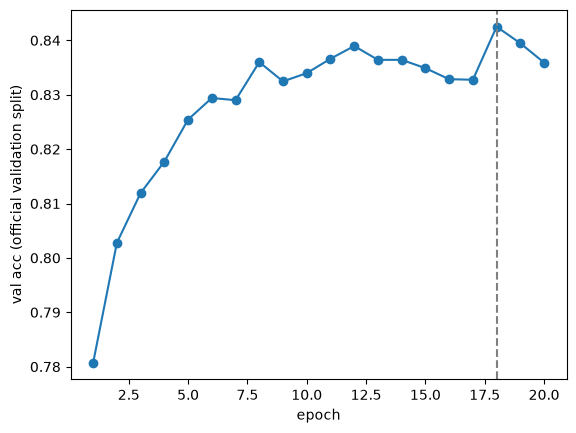

CPU times: user 3min 38s, sys: 1min 7s, total: 4min 46s
Wall time: 16min 1s


In [14]:
%%time
# final model: best CV setting, trained on the FULL training set (~550k pairs);
# number of epochs picked on the official validation split
full_premises = train_df["premise"].tolist()
full_hypotheses = train_df["hypothesis"].tolist()
full_labels = train_df["label"].to_numpy()

# same vectors as st_encode_pairs, but each premise (repeated ~3x in SNLI) is encoded only once
unique_premises = list(dict.fromkeys(full_premises))
U = sentence_model.encode(unique_premises, batch_size=256, convert_to_numpy=True, show_progress_bar=True)
pos = {p: i for i, p in enumerate(unique_premises)}
u = U[[pos[p] for p in full_premises]]
v = sentence_model.encode(full_hypotheses, batch_size=256, convert_to_numpy=True, show_progress_bar=True)
ST_FULL = np.concatenate([u, v], axis=1).astype(np.float32)
del U, u, v
print("full training set:", ST_FULL.shape)

args = dict(MLP_ARGS, dropout=float(FINAL.dropout), lr=float(FINAL.lr))
final_curve, best_val, best_epoch, best_state = [], -1.0, None, None
for e, m in mlp_epochs(ST_FULL, full_labels, FINAL.hidden, MAX_EPOCHS, **args):
    va = accuracy_score(val_labels, predict(m, ST_VAL))
    final_curve.append(va)
    print(f"epoch {e:>2}  val {va:.4f}")
    if va > best_val:
        best_val, best_epoch = va, e
        best_state = {k: t.detach().clone() for k, t in m.state_dict().items()}

m.load_state_dict(best_state)
final_model = m
print(f"\nbest epoch {best_epoch}: train {accuracy_score(full_labels, predict(final_model, ST_FULL)):.4f}  val {best_val:.4f}")

plt.plot(range(1, MAX_EPOCHS + 1), final_curve, marker="o")
plt.axvline(best_epoch, ls="--", c="grey"); plt.xlabel("epoch"); plt.ylabel("val acc (official validation split)"); plt.show()

In [15]:
%%time
# same final procedure for st_mlp1 and st_loglin: train on the full training set, score on the official validation split
final_results = {"st_mlp2": best_val}

# st_mlp1: 1 hidden layer, our default settings; epoch picked on the validation split
best1, ep1, state1 = -1.0, None, None
for e, m1 in mlp_epochs(ST_FULL, full_labels, (128,), MAX_EPOCHS, **MLP_ARGS):
    va = accuracy_score(val_labels, predict(m1, ST_VAL))
    print(f"st_mlp1 epoch {e:>2}  val {va:.4f}")
    if va > best1:
        best1, ep1 = va, e
        state1 = {k: t.detach().clone() for k, t in m1.state_dict().items()}
m1.load_state_dict(state1)
final_results["st_mlp1"] = best1

# st_loglin
lr_model = fit_loglin(ST_FULL, full_labels)
final_results["st_loglin"] = accuracy_score(val_labels, predict(lr_model, ST_VAL))

pd.Series(final_results, name="val accuracy (full training set)").round(4)

st_mlp1 epoch  1  val 0.7259
st_mlp1 epoch  2  val 0.7640
st_mlp1 epoch  3  val 0.7761
st_mlp1 epoch  4  val 0.7866
st_mlp1 epoch  5  val 0.7900
st_mlp1 epoch  6  val 0.7979
st_mlp1 epoch  7  val 0.8014
st_mlp1 epoch  8  val 0.8051
st_mlp1 epoch  9  val 0.8049
st_mlp1 epoch 10  val 0.8090
st_mlp1 epoch 11  val 0.8134
st_mlp1 epoch 12  val 0.8134
st_mlp1 epoch 13  val 0.8155
st_mlp1 epoch 14  val 0.8150
st_mlp1 epoch 15  val 0.8162
st_mlp1 epoch 16  val 0.8173
st_mlp1 epoch 17  val 0.8166
st_mlp1 epoch 18  val 0.8193
st_mlp1 epoch 19  val 0.8200
st_mlp1 epoch 20  val 0.8237
CPU times: user 9min 45s, sys: 51.8 s, total: 10min 37s
Wall time: 11min 44s


KeyboardInterrupt: 

In [ ]:
# test set: used once, for the final numbers
test_pairs = list(zip(test_df["premise"], test_df["hypothesis"]))
ST_TEST = st_encode_pairs(test_pairs)   # ~10k pairs, about a minute
test_labels = test_df["label"].to_numpy()
pd.Series({name: accuracy_score(test_labels, predict(model, ST_TEST))
           for name, model in [("st_mlp2", final_model), ("st_mlp1", m1), ("st_loglin", lr_model)]},
          name="test accuracy").round(4)

In [16]:
ST_TEST = st_encode_pairs(list(zip(test_df["premise"], test_df["hypothesis"])))
print("st_mlp2 test accuracy:", accuracy_score(test_df["label"].to_numpy(), predict(final_model, ST_TEST)))

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

st_mlp2 test accuracy: 0.8357084690553745


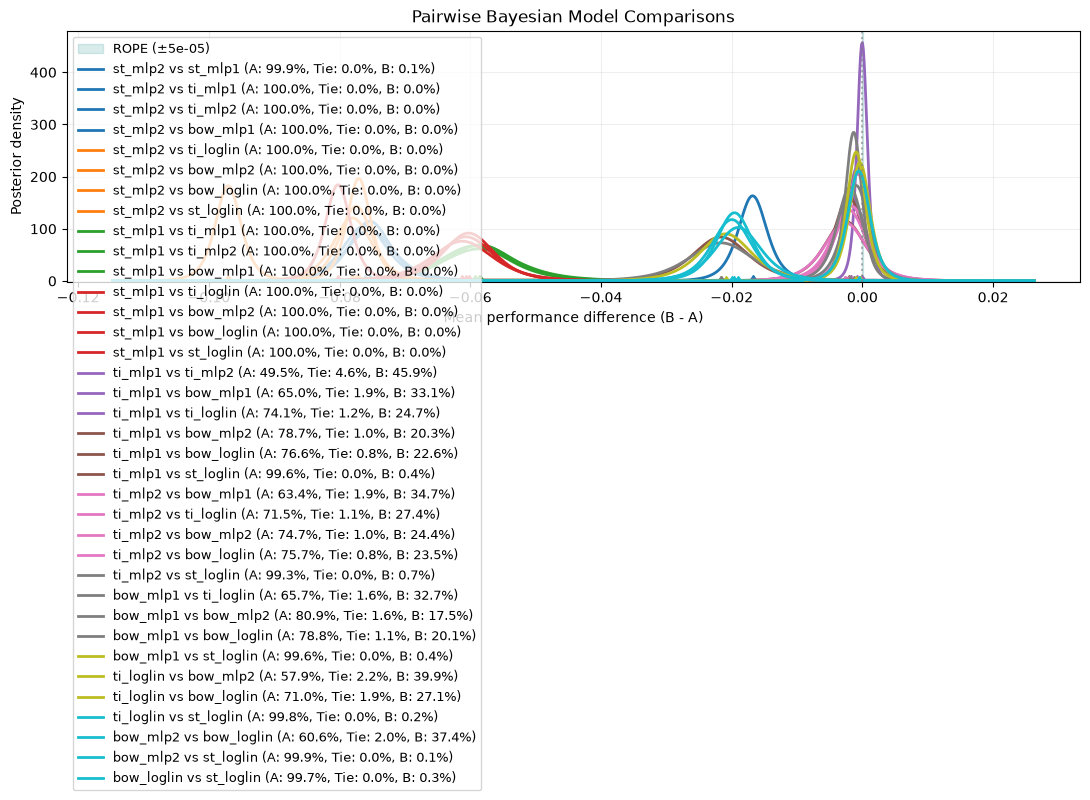